In [38]:
import pandas
from matplotlib import pyplot
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

from kmodes.kmodes import KModes
import prince
import seaborn

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

from sklearn.tree import DecisionTreeClassifier, plot_tree

from statsmodels.stats.proportion import proportions_ztest


In [2]:
pyplot.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 300,
    'axes.spines.top': False,    # Remove top border for clean academic look
    'axes.spines.right': False,  # Remove right border
})

# Part 1: Read and verify the data

In [3]:
shopping_data = pandas.read_csv('consumer_shopping_behavior_survey.csv')

#I will view the first 5 rows of the dataset to ensure it loaded properly.
shopping_data.head(5)

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [4]:
shopping_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    object 
 2   Age                                 478 non-null    object 
 3   Gender                              484 non-null    object 
 4   Occupation_Status                   479 non-null    object 
 5   Country_Region                      480 non-null    object 
 6   Monthly_Income_Range                479 non-null    object 
 7   Shop_Most_Where                     484 non-null    object 
 8   Online_Shopping_Frequency           481 non-null    object 
 9   Preferred_Platform                  486 non-null    object 
 10  Primary_Device                      492 non-null    object 
 11  Top_Spending_Category               476 non-n

# Part 2: Clean the data

In [5]:
# The timestamp column should be a datetime
shopping_data.Timestamp = pandas.to_datetime(shopping_data.Timestamp, format='mixed')

# Age should be a numeric column so we will convert it.
shopping_data.Age = pandas.to_numeric(shopping_data.Age, errors='coerce')




In [6]:
shopping_data.describe(include='all')

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
count,500.000000,500,470.000000,484,479,480,479,484,481,486,...,483,480,485,488,457.000000,450.000000,448.000000,446,455,449
unique,NaN,NaN,NaN,3,5,18,4,3,4,4,...,3,5,4,3,NaN,NaN,NaN,4,4,3
top,NaN,NaN,NaN,Male,Student,India,"Under $1,000",Equal mix,Occasionally,Global marketplace (Amazon etc.),...,Sometimes,Under $50,Digital wallet,"No, never",NaN,NaN,NaN,More variety,Try product before buying,Online
freq,NaN,NaN,NaN,256,238,66,257,248,240,141,...,213,179,183,290,NaN,NaN,NaN,170,145,218
mean,250.500000,2026-07-14 00:02:15.210000128,25.019149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,7.126915,6.160000,2.187500,NaN,NaN,NaN
min,1.000000,2026-01-07 05:06:37,16.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2.000000,1.000000,1.000000,NaN,NaN,NaN
25%,125.750000,2026-06-25 17:37:29.500000,20.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,6.000000,5.000000,1.000000,NaN,NaN,NaN
50%,250.500000,2026-07-21 13:54:52,22.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,7.000000,6.000000,2.000000,NaN,NaN,NaN
75%,375.250000,2026-08-16 15:55:25.249999872,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,8.000000,7.000000,3.000000,NaN,NaN,NaN
max,500.000000,2026-12-08 23:34:43,50.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,10.000000,10.000000,4.000000,NaN,NaN,NaN


In [7]:
# I am going to use "Likely to buy after ad score" as my target variable
# I am going to get rid of all rows that are missing that score

shopping_data = shopping_data.dropna(subset=['Likely_To_Buy_After_Ad_Score'])

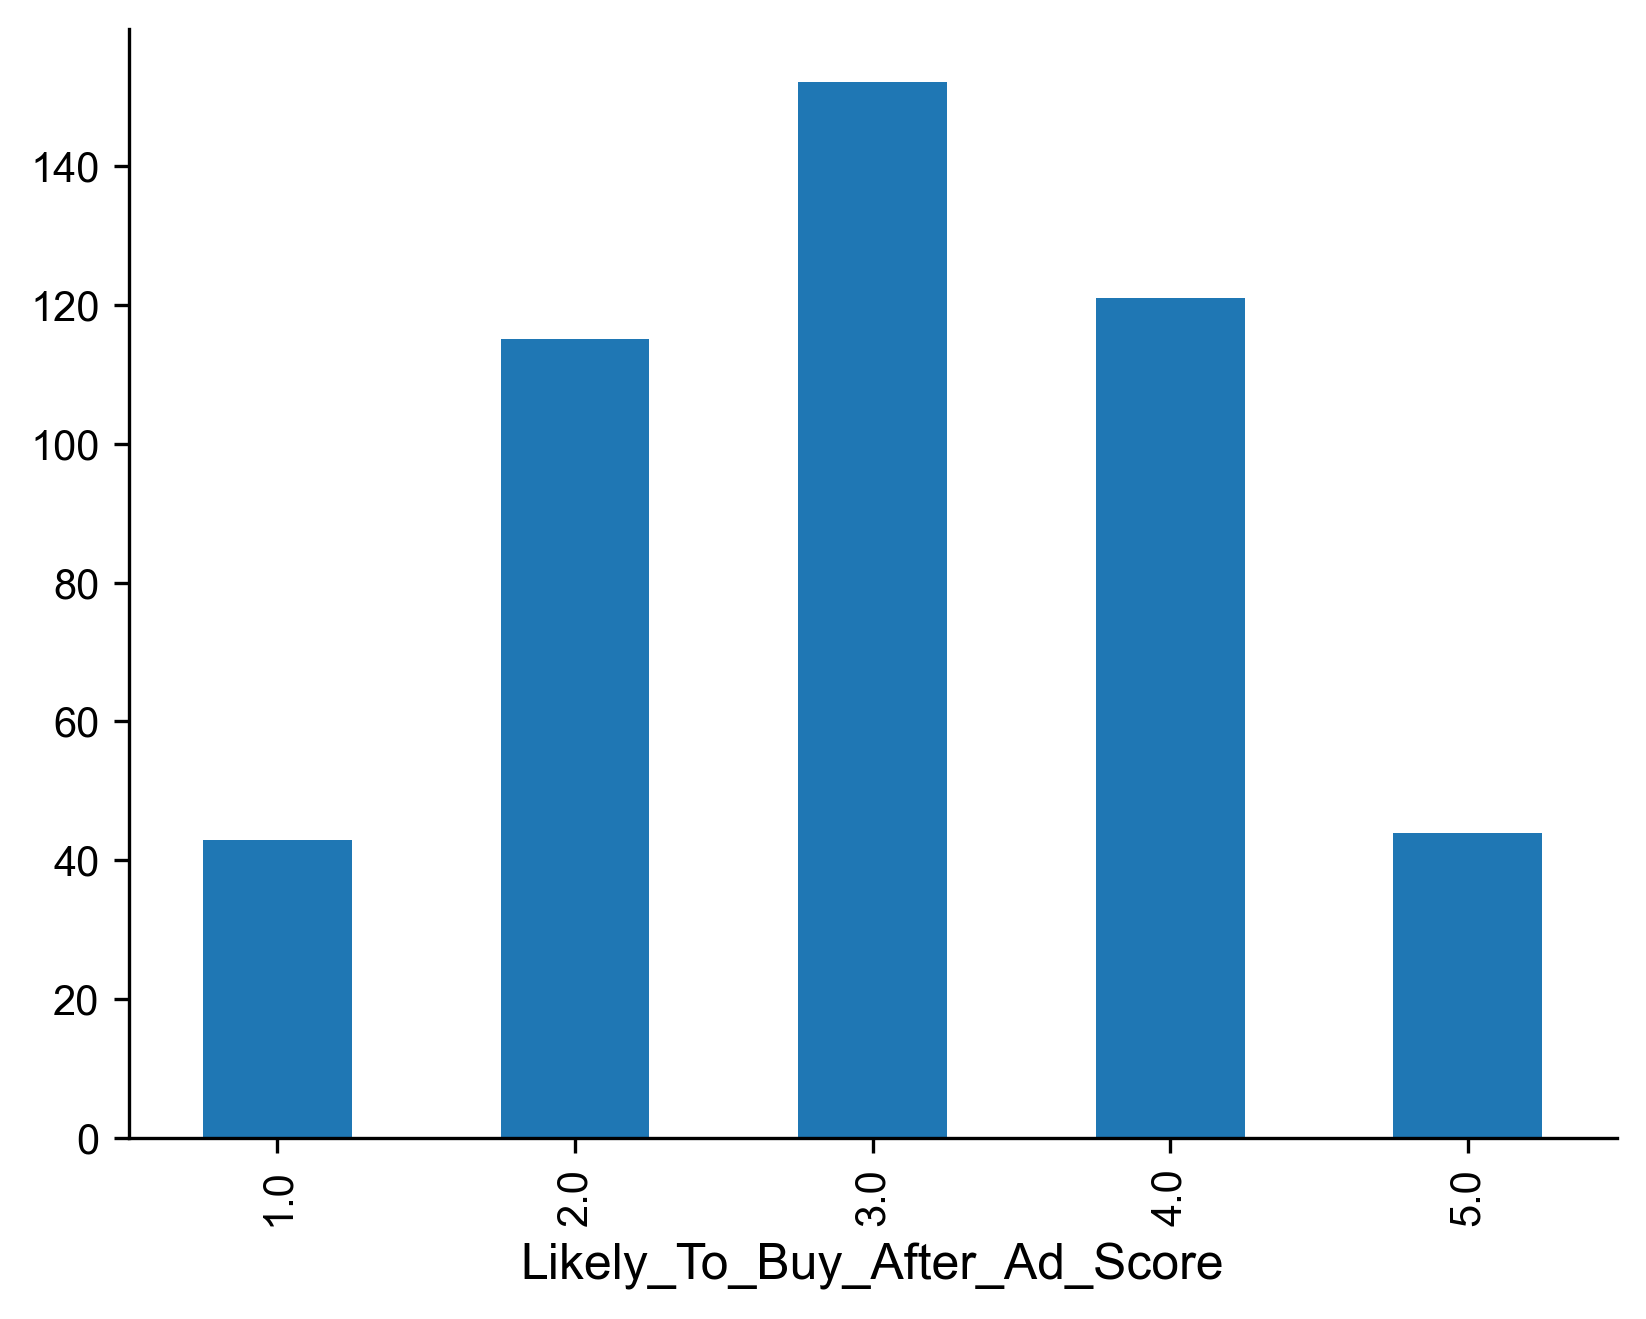

In [44]:
shopping_data['Likely_To_Buy_After_Ad_Score'].value_counts().sort_index().plot(kind='bar')

pyplot.savefig('target.png')

In [9]:
# If I remove the rest of the missing values there will only be about 160 rows left.
# Instead, I am going to impute data for the rest of the missing columns.

for col in shopping_data.columns:
    # for categorical columns I will impute the mode (most common value)
    if shopping_data[col].dtype == 'object':
        shopping_data[col] = shopping_data[col].fillna(shopping_data[col].mode().iloc[0])
    # for missing numeric columns I will replacce missing with median.
    if shopping_data[col].dtype in ['int64', 'float64']:
        shopping_data[col] = shopping_data[col].fillna(shopping_data[col].median())

In [10]:
shopping_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 475 entries, 0 to 498
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Response_ID                         475 non-null    int64         
 1   Timestamp                           475 non-null    datetime64[ns]
 2   Age                                 475 non-null    float64       
 3   Gender                              475 non-null    object        
 4   Occupation_Status                   475 non-null    object        
 5   Country_Region                      475 non-null    object        
 6   Monthly_Income_Range                475 non-null    object        
 7   Shop_Most_Where                     475 non-null    object        
 8   Online_Shopping_Frequency           475 non-null    object        
 9   Preferred_Platform                  475 non-null    object        
 10  Primary_Device                 

In [11]:
# I will use one-hot-encodeing to encode all of the categorical variables
shopping_data_encoded = pandas.get_dummies(shopping_data)

# Part 3: Check for any initial relationships

In [12]:
correlations = shopping_data_encoded.corr()['Likely_To_Buy_After_Ad_Score']

with pandas.option_context('display.max_rows', None):
    correlations = pandas.DataFrame(correlations)
    correlations.to_csv('correlations.csv')
    print(correlations)



                                                    Likely_To_Buy_After_Ad_Score
Response_ID                                                            -0.006738
Timestamp                                                              -0.021712
Age                                                                    -0.187156
Review_Influence_Score                                                  0.394065
Social_Ads_Influence_Score                                              0.459806
Price_Comparison_Frequency                                             -0.034918
Discount_Importance_Score                                              -0.012707
Likely_To_Buy_After_Ad_Score                                            1.000000
Impulse_Purchase_Frequency                                              0.271869
Online_Shopping_Satisfaction_Score                                      0.022560
Trust_In_Online_Reviews_Score                                          -0.013739
Regret_After_Purchase_Freque

In [13]:
cat_columns = shopping_data.select_dtypes(include = ['object']).columns
num_cols = len(cat_columns)
frequency_order = ["never", "sometimes", "often", "always"]

fig, axes = pyplot.subplots(nrows = (num_cols+1)//2, ncols = 2, figsize=(12, num_cols*3))
axes = axes.flatten()

for i, col in enumerate(cat_columns):
    shopping_data[col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_ylabel('Count')
pyplot.tight_layout()
fig.savefig('bar_plots.png')


# Part 4: Clustering

BEcause the data is mostly categorical, I will us KModes as the clusterign algorithm instead of Kmeans

In [14]:
# Choose and scale the data for the clustering algorithm)
clustering_data = shopping_data.drop(columns= ['Response_ID', 'Timestamp'])

# I will use costs from varius KModes models to choose the best number of clusters.
# Make an empty list to hold the costs as they are calculated
costs = []

# set the range of k-values to test
k_values = range(2,15)

# populate the list of costs for each k value
for k in k_values:
    kmodes = KModes(n_clusters=k, random_state=19).fit(clustering_data)
    costs.append(kmodes.cost_)

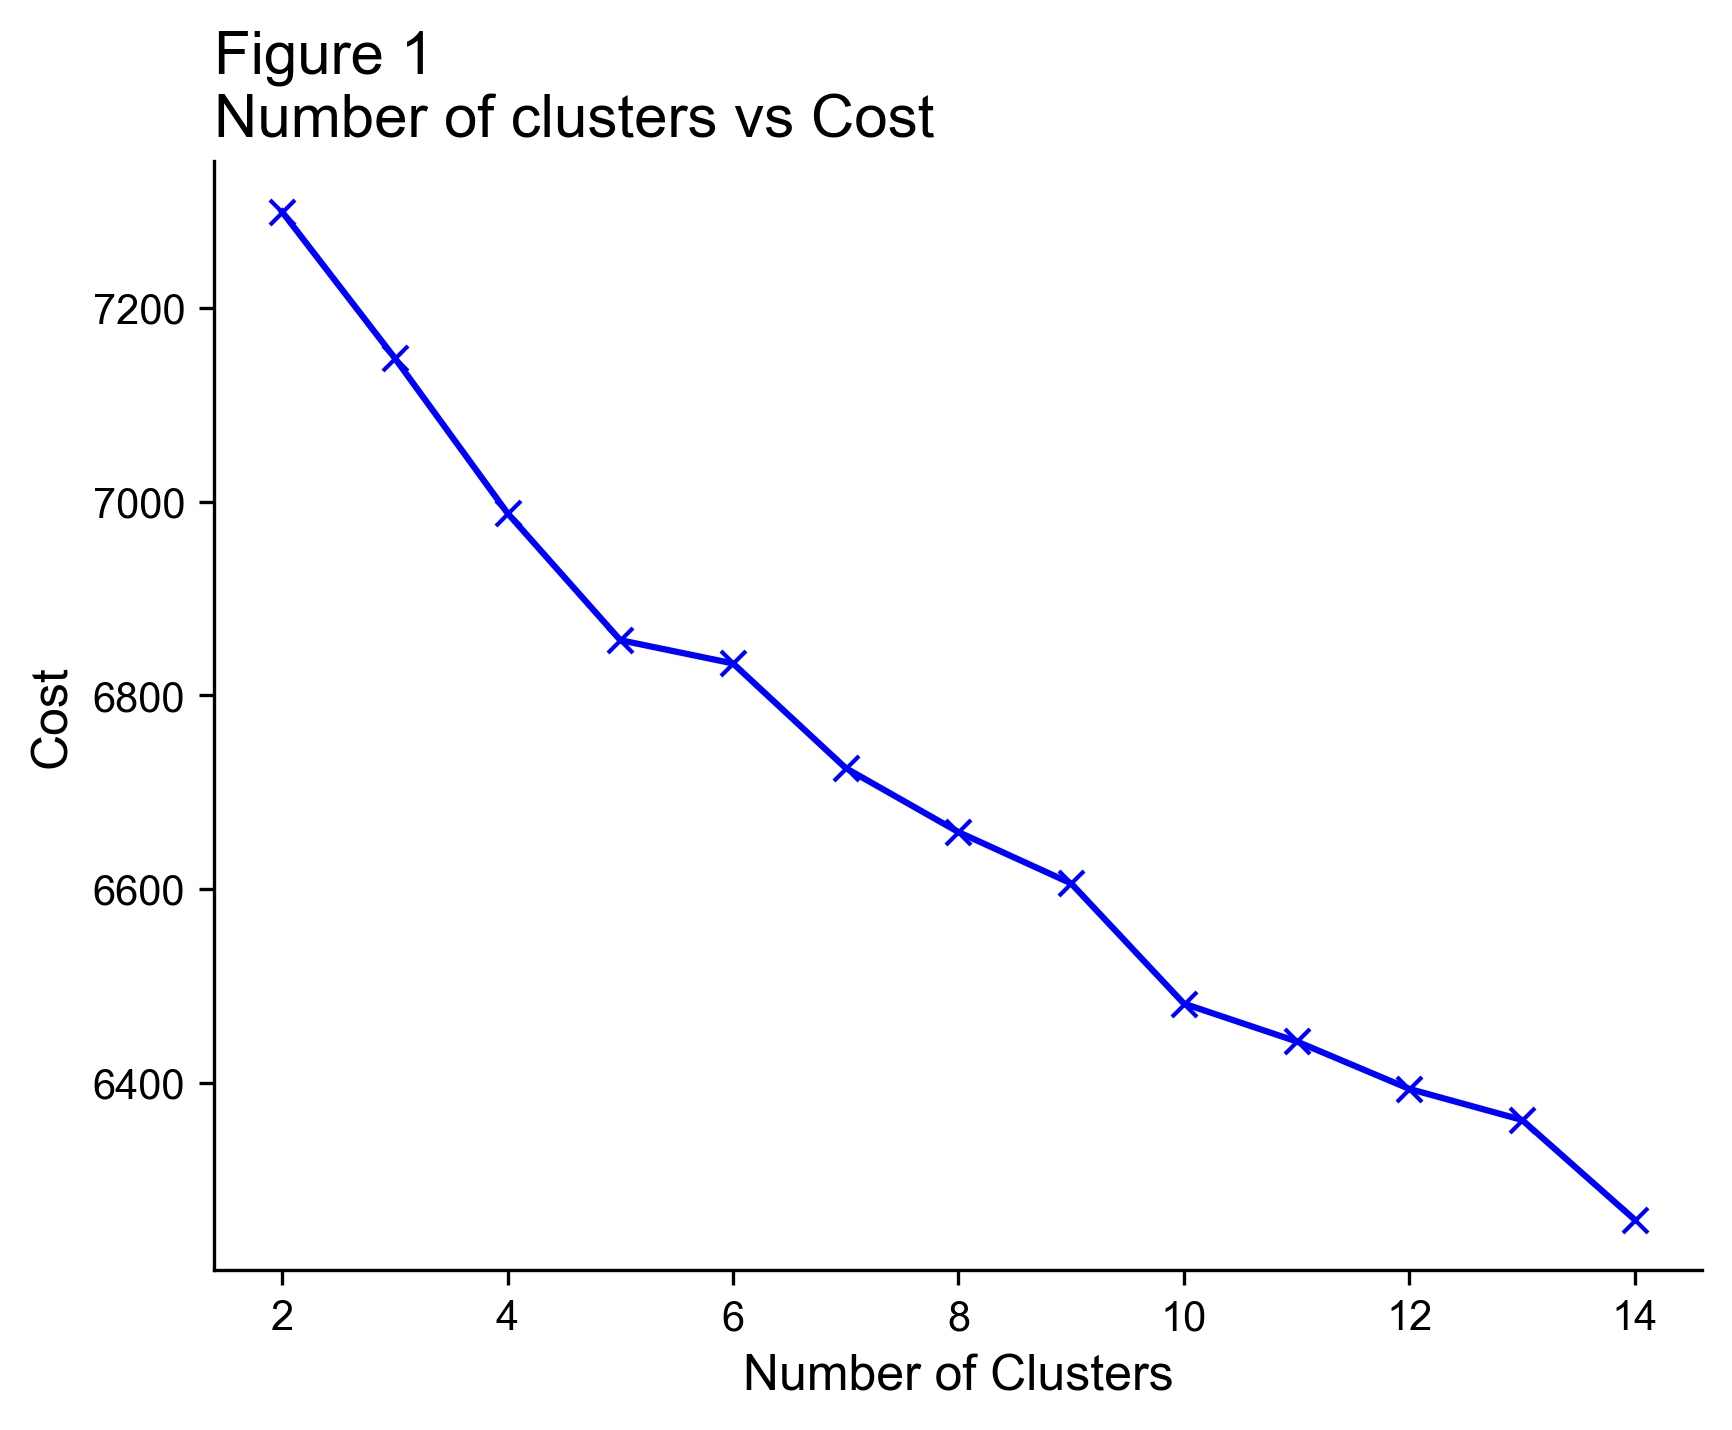

In [15]:
# We will use the elbow method to identify the 
pyplot.plot(k_values, costs, 'bx-')
pyplot.title('Figure 1\nNumber of clusters vs Cost', loc = 'left')
pyplot.xlabel('Number of Clusters')
pyplot.ylabel('Cost')

pyplot.savefig('costs_graph.png')

While the Cost graph seems to be steadily decreasing, k=5 seems to represent a slight inflection point, or elbow, in the graph. I will exam the clusters created by k=5 groups to make sure they seem to be logical ways to cluster the dataset.

In [16]:
kmodes_optimal = KModes(n_clusters=5, random_state=19).fit(clustering_data)
cluster_labels = kmodes_optimal.fit_predict(clustering_data)

df_clustered = clustering_data.copy()
df_clustered['Cluster'] = cluster_labels

In [17]:
with pandas.option_context('display.max_columns', None):
    # Create a DataFrame of the cluster centroids (modes)
    cluster_modes = pandas.DataFrame(kmodes_optimal.cluster_centroids_, columns=clustering_data.columns)
    cluster_modes.index.name = 'Cluster'
    # Display the most common attribute values for each cluster
    print("--- Cluster Modes (Dominant Characteristics) ---")
    print(cluster_modes)

--- Cluster Modes (Dominant Characteristics) ---
          Age  Gender Occupation_Status Country_Region Monthly_Income_Range  \
Cluster                                                                       
0        21.0    Male           Student  United States         Under $1,000   
1        20.0  Female           Student          India         Under $1,000   
2        21.0  Female           Student         Poland         Under $1,000   
3        18.0    Male           Student          India         Under $1,000   
4        22.0    Male           Student          India         Under $1,000   

        Shop_Most_Where Online_Shopping_Frequency  \
Cluster                                             
0             Equal mix              Occasionally   
1             Equal mix              Occasionally   
2             Equal mix                     Often   
3           Online only              Occasionally   
4             Equal mix              Occasionally   

                       Pr

These clusters all look very similar to me. Therefore, I will use MCA to visualise whether the 5 clusters actualy look like meaningful seperate groups.

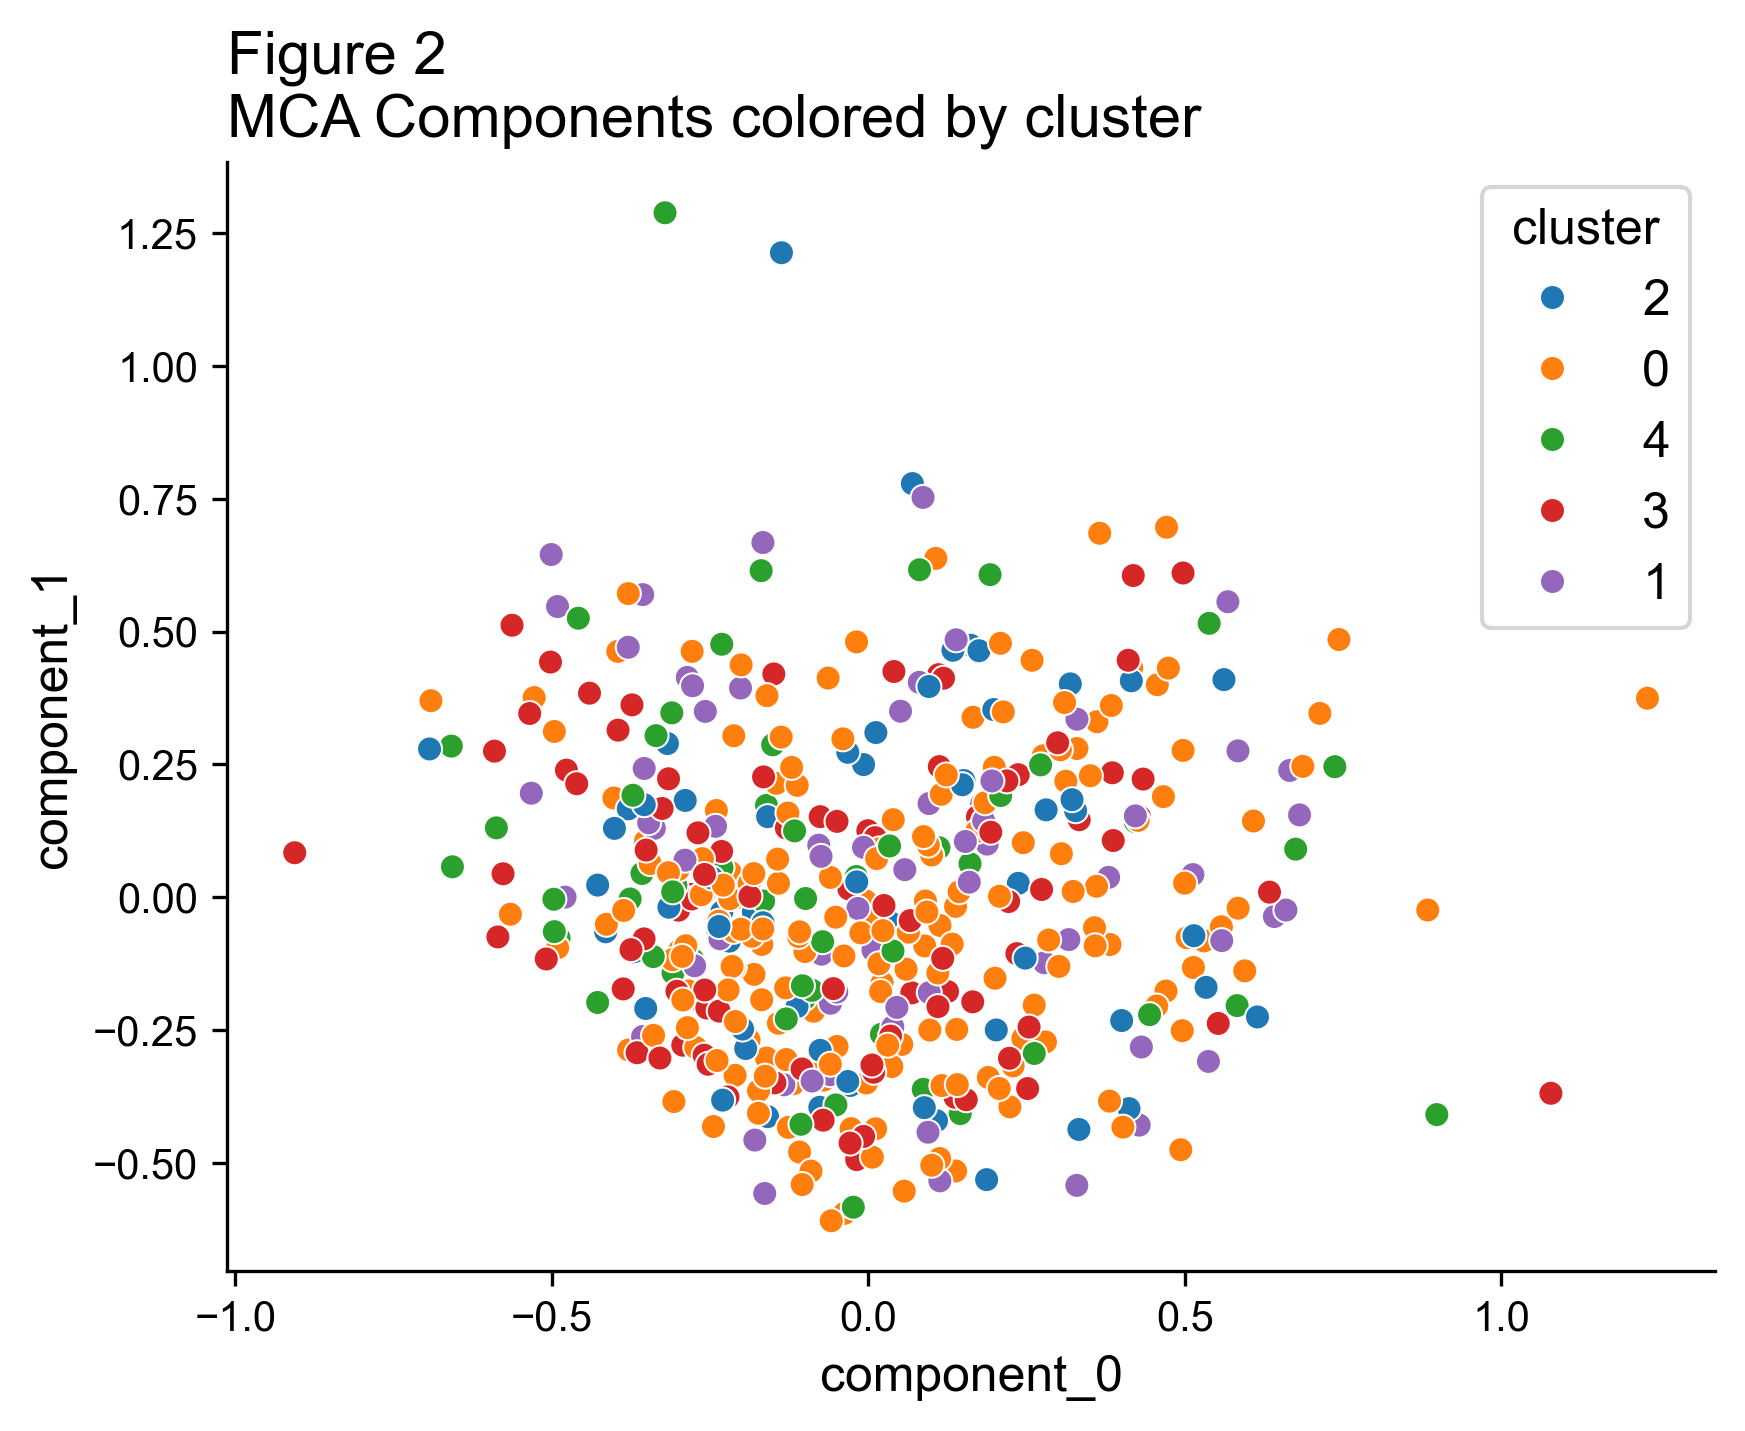

In [18]:
mca_components = prince.MCA(n_components=2, random_state=19).fit(clustering_data)

row_coordinates = mca_components.row_coordinates(clustering_data)
row_coordinates.columns = ['component_0', 'component_1']

row_coordinates['cluster'] = cluster_labels.astype(str)

pyplot.figure()
seaborn.scatterplot(data = row_coordinates,
                    x = 'component_0',
                    y = 'component_1',
                    hue = 'cluster')
pyplot.title('Figure 2\nMCA Components colored by cluster', loc = 'left')

pyplot.savefig('MCA_graph.png')

Based on this MCA graph, I am not convinced that the 5 clusters are meaningful at all.

# Classification

In [19]:
Modeling_features = shopping_data_encoded.drop(columns= ['Response_ID', 'Timestamp', 'Likely_To_Buy_After_Ad_Score'])
Modeling_target =  shopping_data_encoded['Likely_To_Buy_After_Ad_Score']

X_train, X_test, y_train, y_test = train_test_split(Modeling_features, Modeling_target, test_size=.20, random_state=19)

## KNN model

In [20]:
KNN_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))])

KNN_pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,feature_range,"(0, ...)"
,copy,True
,clip,False
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [21]:
print(f'The accuracy of the preliminary model is {KNN_pipeline.score(X_test,y_test)}')

The accuracy of the preliminary model is 0.14736842105263157


In [22]:
# I will try to find a better k-value.

search_space = [{"knn__n_neighbors": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35]}]

classifier = GridSearchCV(KNN_pipeline, search_space, cv=5, verbose=0).fit(X_train, y_train)
best_k = classifier.best_estimator_.get_params()["knn__n_neighbors"]

print(f'Best k value is {best_k}.')

Best k value is 25.


In [23]:
KNN_pipeline.set_params(knn__n_neighbors=best_k)

KNN_pipeline.fit(X_train, y_train)

print(f'accuracy = {KNN_pipeline.score(X_test, y_test)}')

accuracy = 0.21052631578947367


The Grid Search showed that the best k-value is 25 and even that gives an accuracy score of 0.21.

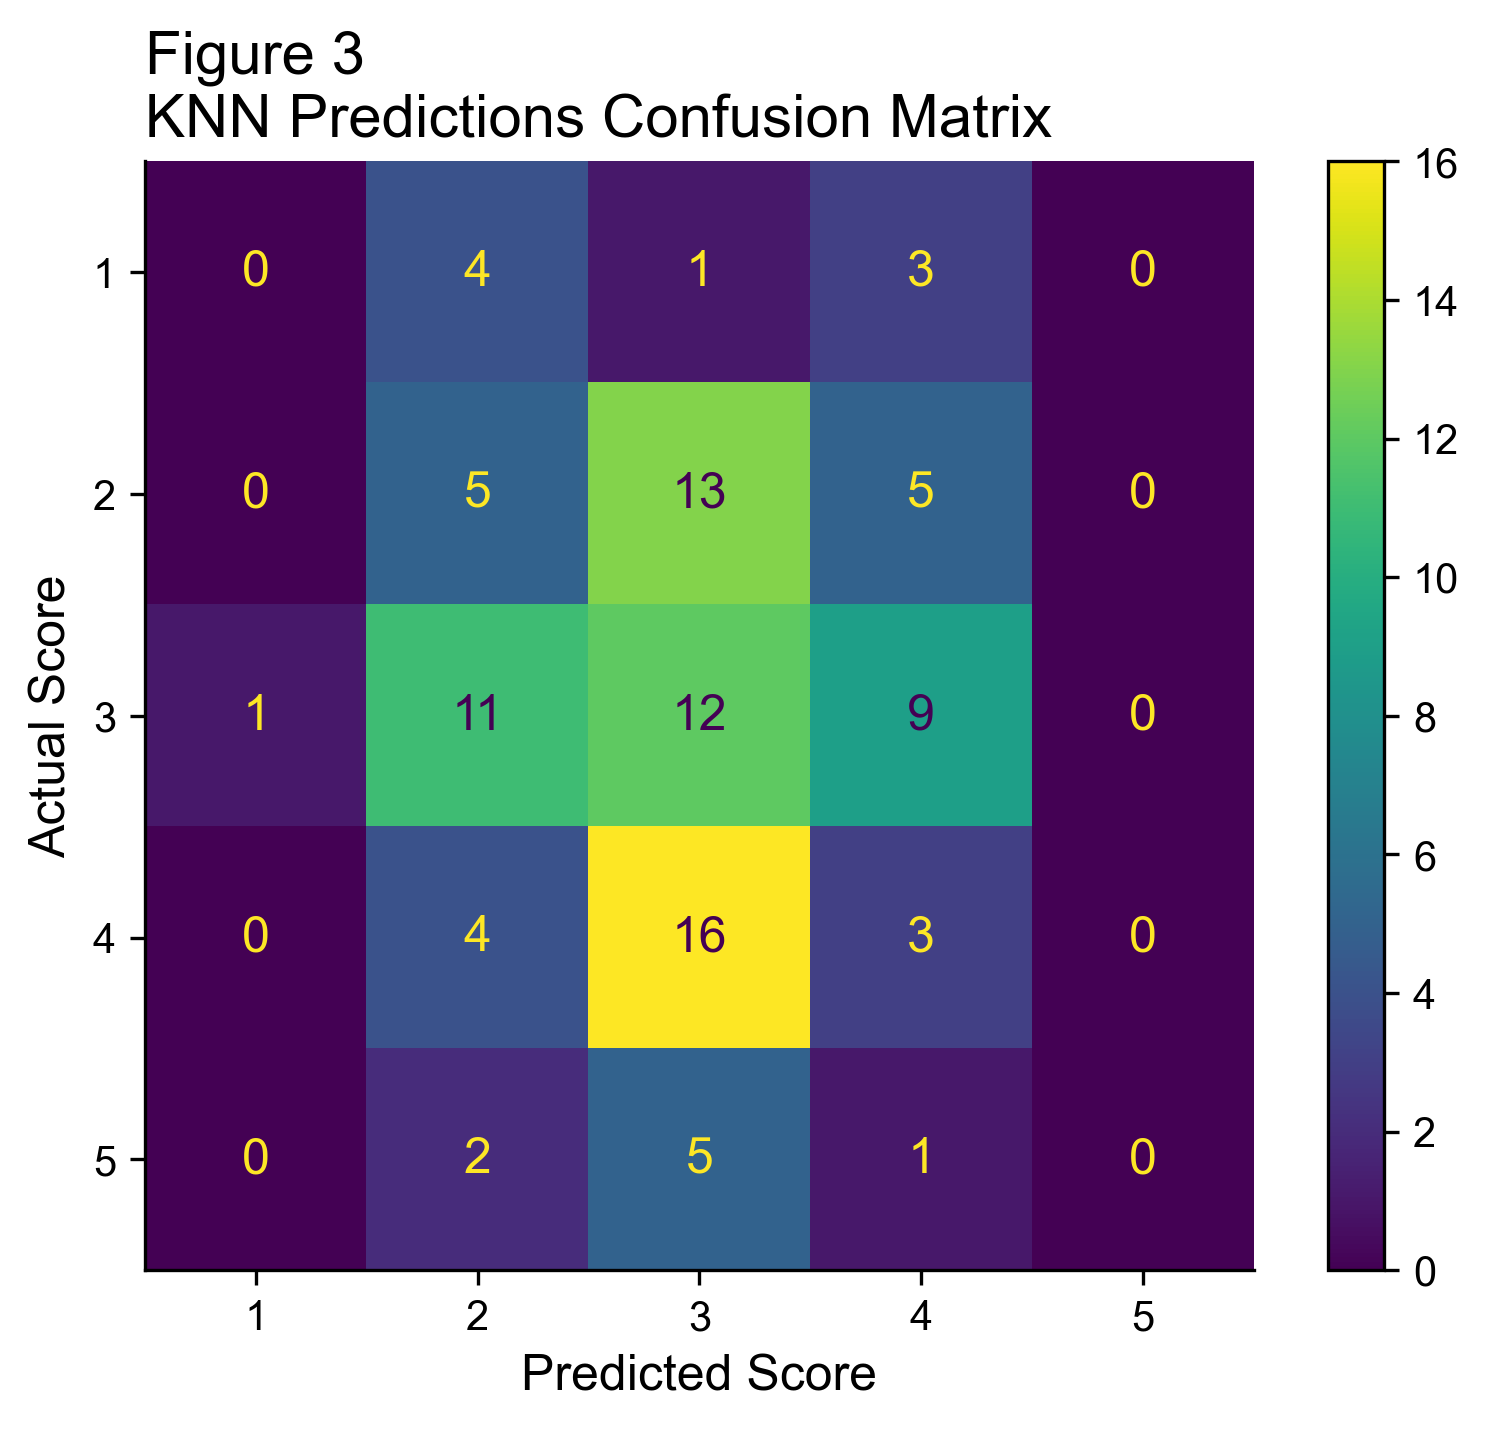

In [24]:
preds = KNN_pipeline.predict(X_test)
category_labels = ['1', '2', '3', '4', '5']
confusion = confusion_matrix(y_test, preds)
ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=category_labels).plot()
pyplot.title('Figure 3\nKNN Predictions Confusion Matrix', loc = 'left')
pyplot.xlabel('Predicted Score')
pyplot.ylabel('Actual Score')

pyplot.savefig ('knn_matrix.png')

The confusion matrix confirms that even the "best" KNN model did a terrible job of predicting Likelyhood to buy after adds.

## Tree Model

In [25]:
dtree = DecisionTreeClassifier(random_state = 19)

dtree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,19
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
preds = dtree.predict(X_test)

print(f'The accuracy score is {dtree.score(X_test, y_test)}')

The accuracy score is 0.35789473684210527


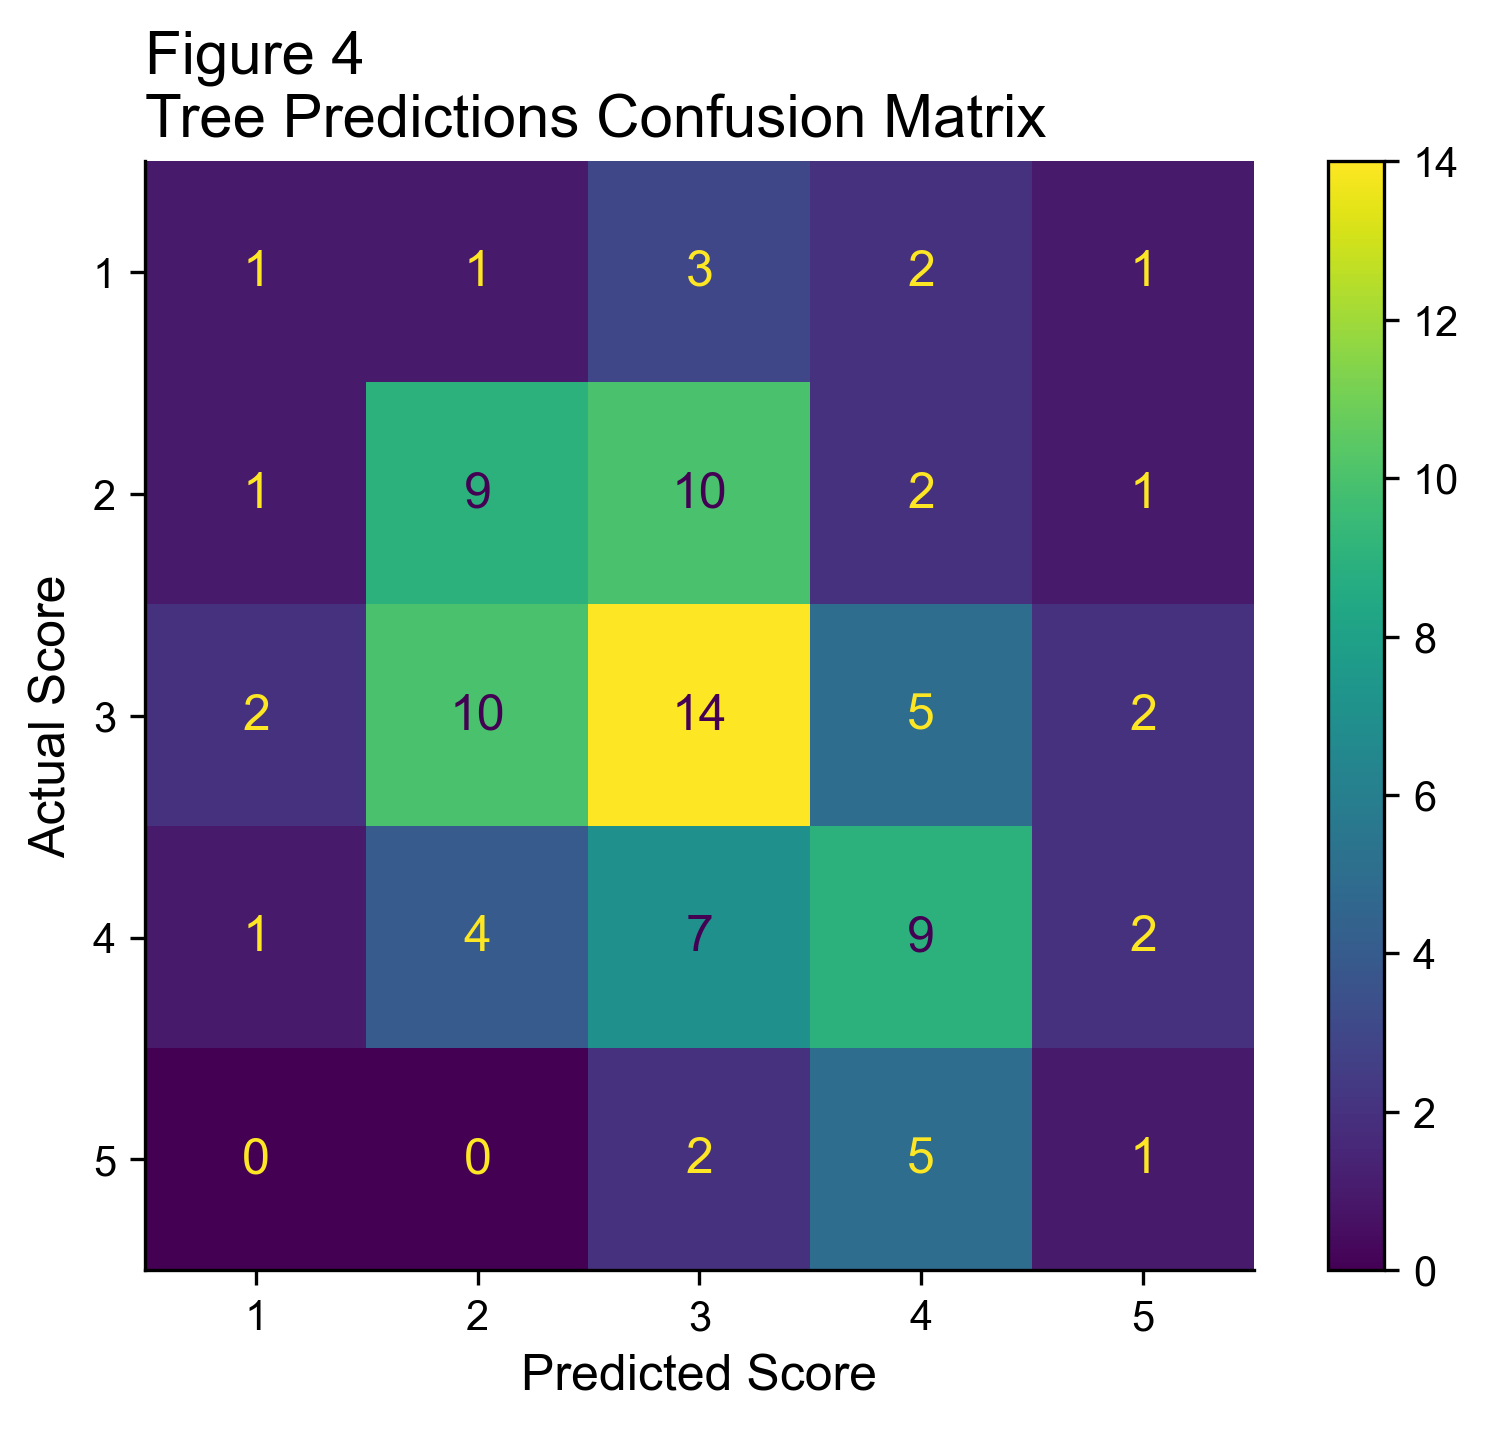

In [27]:
confusion = confusion_matrix(y_test, preds)
category_labels = ['1', '2', '3', '4', '5']

ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=category_labels).plot()
pyplot.title('Figure 4\nTree Predictions Confusion Matrix', loc = 'left')
pyplot.xlabel('Predicted Score')
pyplot.ylabel('Actual Score')
    
pyplot.savefig('tree_matrix.png')

In [28]:
# Because the decidion tree was more accurate than the KNN model, further tuning the tree using a grid search may lead to even better predictions.
parameter_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4],
    'criterion': ['gini', 'entropy']}

tree_grid_search = GridSearchCV(dtree, param_grid = parameter_grid, cv = 5, scoring = 'accuracy')
tree_grid_search.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=19)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [29]:
tree_grid_search.best_params_

{'criterion': 'entropy',
 'max_depth': 3,
 'min_samples_leaf': 1,
 'min_samples_split': 2}

In [30]:
best_tree = tree_grid_search.best_estimator_
preds = best_tree.predict(X_test)

In [31]:
best_tree.score(X_test, y_test)

0.3684210526315789

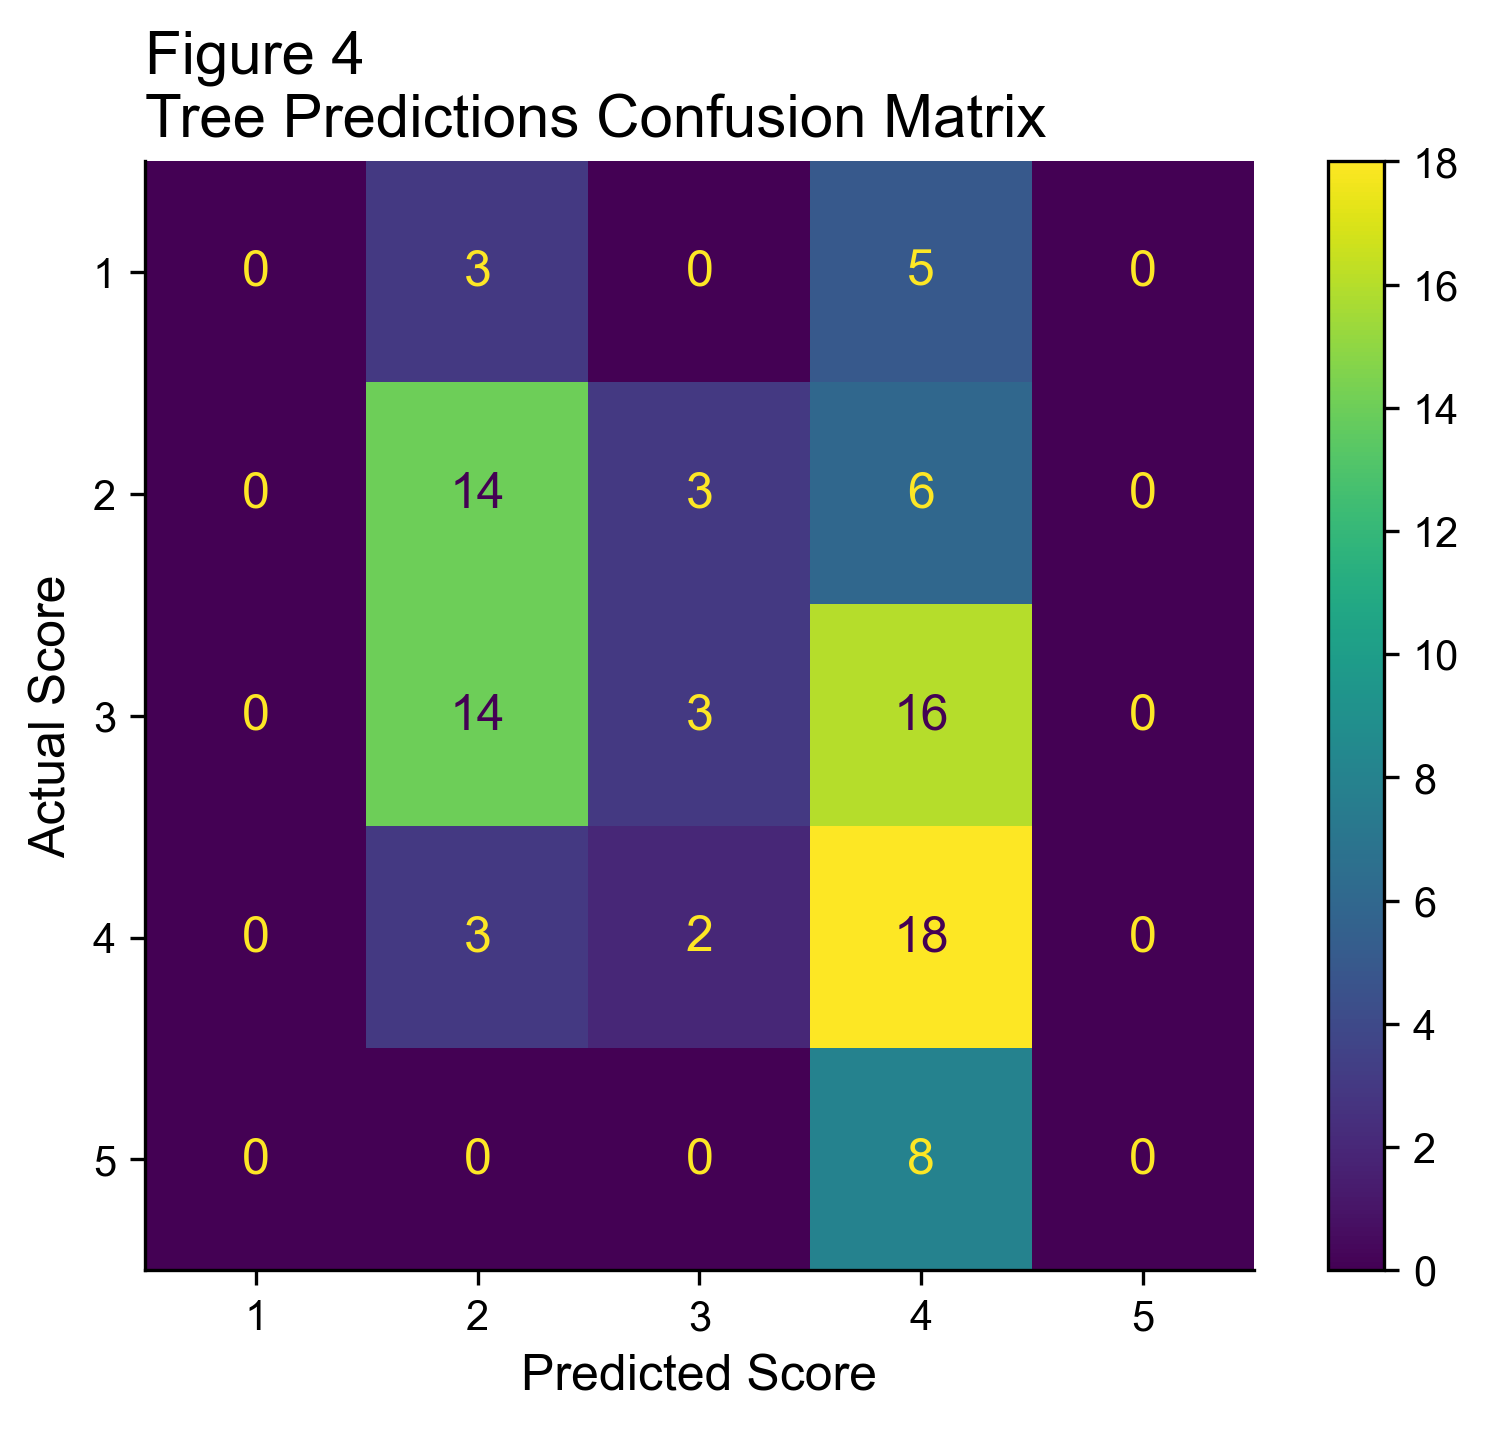

In [32]:
confusion = confusion_matrix(y_test, preds)
category_labels = ['1', '2', '3', '4', '5']

ConfusionMatrixDisplay(confusion_matrix=confusion, display_labels=category_labels).plot()
pyplot.title('Figure 4\nTree Predictions Confusion Matrix', loc = 'left')
pyplot.xlabel('Predicted Score')
pyplot.ylabel('Actual Score')
    
pyplot.savefig('best_tree_matrix.png')

### Significance test

In [33]:
# calculate pcc for the y_test data
counts = y_test.value_counts()
total = counts.sum()

pcc = sum((c/total)**2 for c in counts)

pcc

np.float64(0.25207756232686984)

In [34]:
correct_preds = accuracy_score(y_test, preds, normalize = False)

In [35]:
z_stat, p_value = proportions_ztest(
    count = correct_preds,
    nobs = total,
    value = pcc,
    alternative= 'larger')

p_value

np.float64(0.00936625466563587)

## Feature Importance
Because the decision tree is the better of the two models, I will use it to figure out which features if the dataset have the biggest effect on predicting whether the customer will purchase after seeing an ad.

In [42]:
importance_dataframe = pandas.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_tree.feature_importances_
}).sort_values(by='Importance', ascending=False)

#because the training data was oone-hot-encoded, I will need to recombine the importance scores from each value of each variable.
grouped_importances = pandas.DataFrame(importance_dataframe.groupby(importance_dataframe['Feature'].str.rsplit('_', n=1).str[0])['Importance'].sum().sort_values(ascending = False))

grouped_importances.to_csv('importance scores.csv')

grouped_importances

,Importance
Feature,
Social_Ads_Influence,0.495521
Review_Influence,0.194168
Avg_Monthly_Spend_NonEssentials,0.095236
Country_Region,0.094239
Age,0.073528
Trust_In_Online_Reviews,0.047309
Best_Shopping_Mode,0.000000
Impulse_Purchase,0.000000
Discount_Importance,0.000000


## Decision Tree Plot

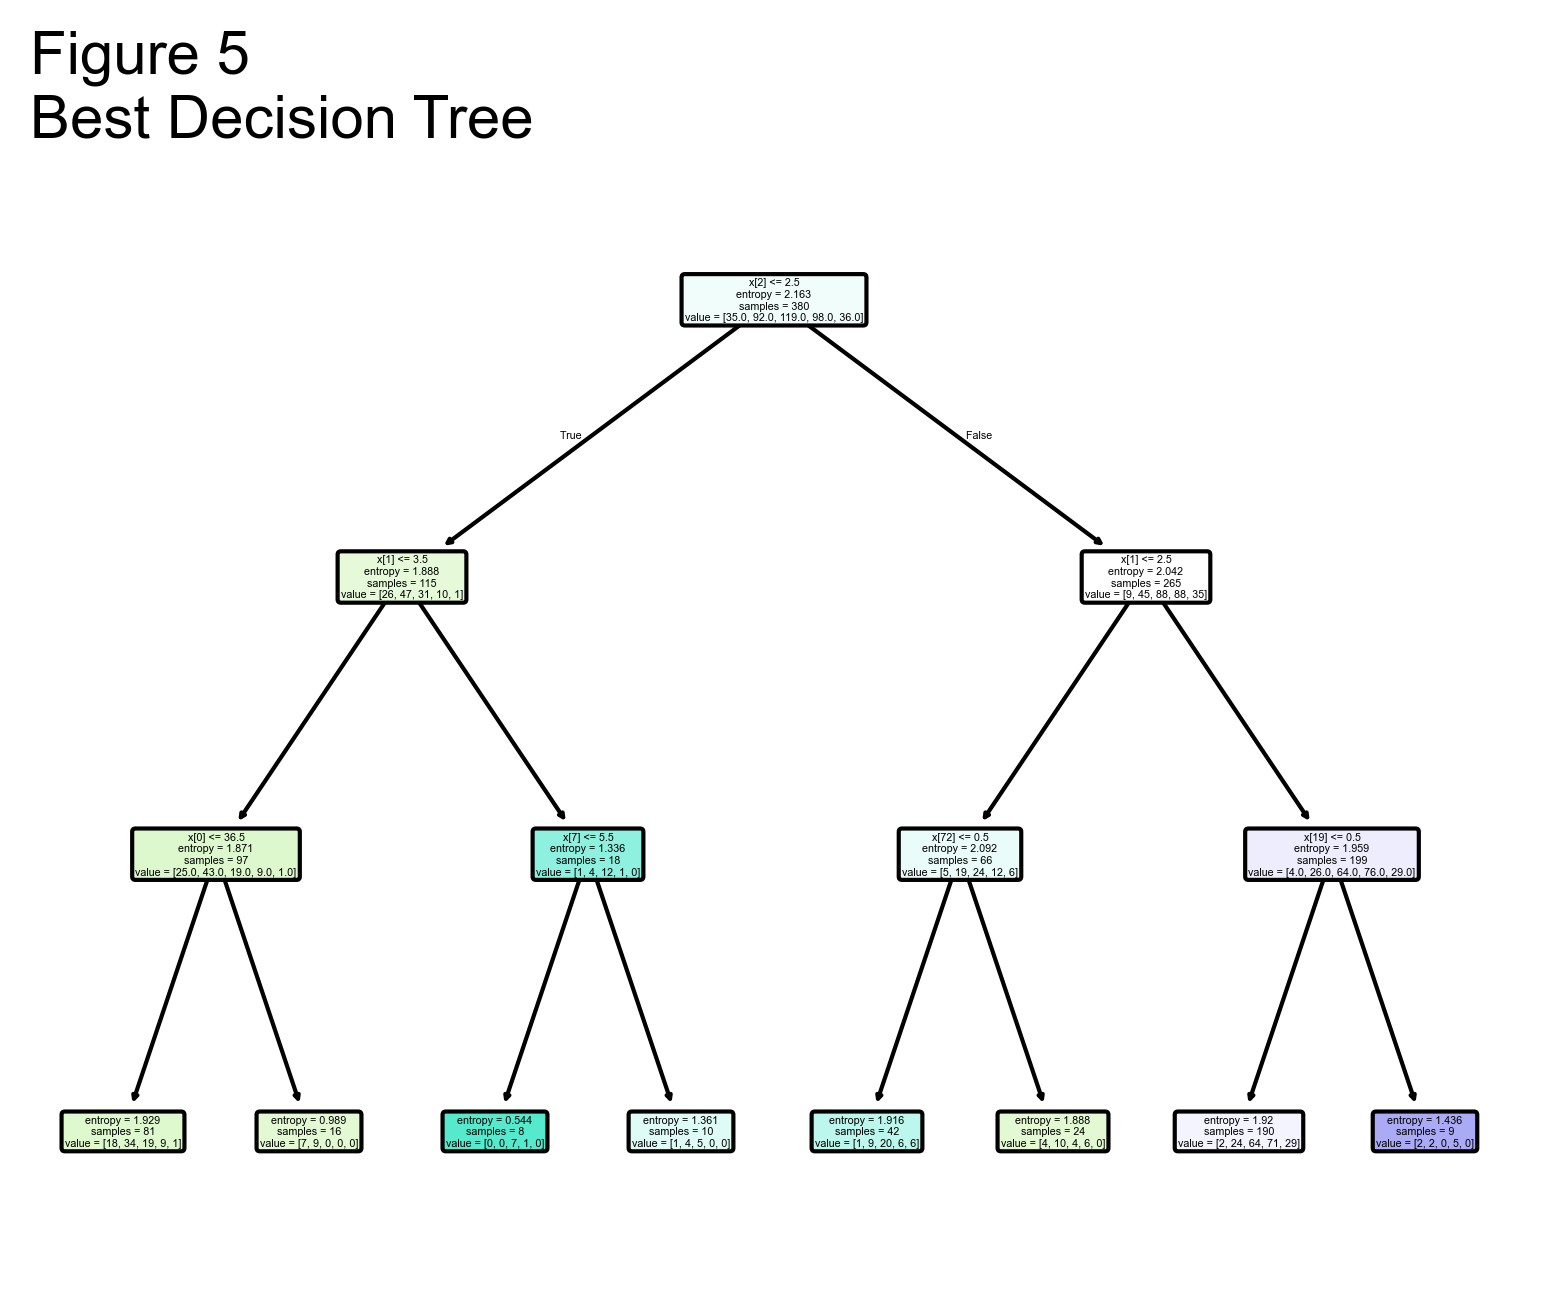

In [40]:
plot_tree(best_tree, filled = True, rounded = True)
pyplot.title('Figure 5\nBest Decision Tree', loc = 'left')

pyplot.savefig('decision tree plot.png')